In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load CSV
try:
    df = pd.read_excel("../../Datasets/excel/2dSpoofingDataset/GPS_Data_Simplified_2D_Feature_Map.xlsx")
except FileNotFoundError:
    print("Error: The file '../Datasets/excel/GPS_Data_Simplified_2D_Feature_Map.xlsx' was not found.")
    print("Please make sure the path is correct.")
    exit()

In [3]:
print(df.head())
print(df.info())

   PRN           DO             PD         RX            TOW            CP  \
0    6  1160.671408 -238359.543282  491568.00  491568.000795 -24660.263293   
1    6  1157.827808 -238363.921192  491568.02  491568.020795 -24683.468520   
2    6  1161.135932 -238368.638615  491568.04  491568.040795 -24706.687357   
3    6  1161.156617 -238373.391775  491568.06  491568.060795 -24729.920039   
4    6  1160.690893 -238378.127066  491568.08  491568.080795 -24753.153999   

          EC         LC         PC        PIP          PQP        TCD  \
0  163521.78  170008.81  179294.97  178420.33 -17688.17800  1158.4806   
1  158277.05  160253.09  182106.11  182106.05    158.33333  1160.7948   
2  184442.36  193125.89  208228.02 -205198.30  35391.59000  1157.6909   
3  159812.45  169960.55  187550.72  187543.00  -1701.94400  1161.1343   
4  183557.66  191912.58  208403.50  208330.05  -5532.89990  1161.1759   

         CN0  Output  
0  49.412529       0  
1  49.452686       0  
2  49.480145       0  


In [4]:
# List of variables/features to plot (excluding 'Output')
features = [
    "PRN",      # pseudo-random number
    "DO",       # Doppler shift
    "PD",       # Pseudorange (m)
    "RX",       # Receiver time
    "TOW",      # Time of week at current symbol (s)
    "CP",       # Carrier phase (cycles)
    "EC",       # EC (feature description needed)
    "LC",       # LC (feature description needed)
    "PC",       # PC (feature description needed)
    "PIP",      # PIP (feature description needed)
    "PQP",      # PQP (feature description needed)
    "TCD",      # TCD (feature description needed)
    "CN0",      # Carrier-to-noise ratio (dB-Hz)
]

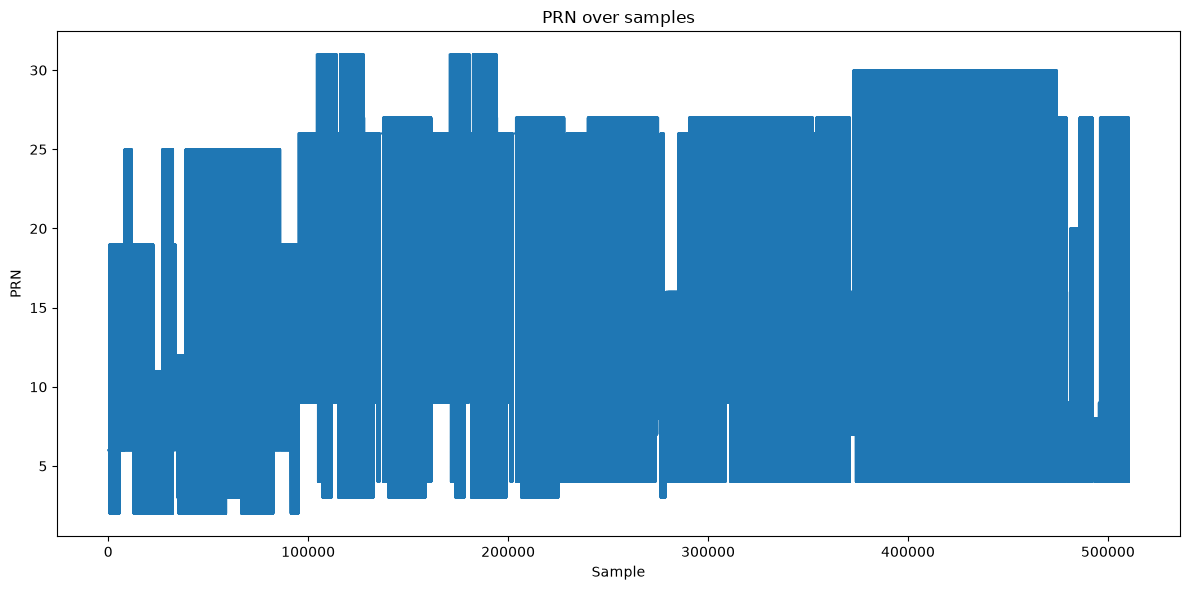

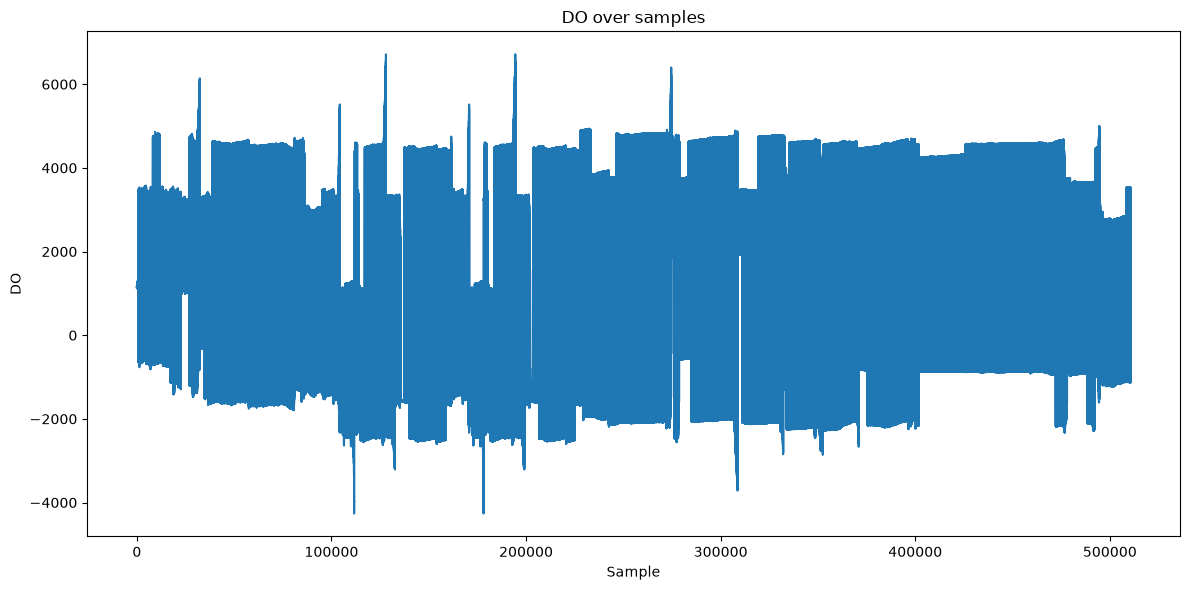

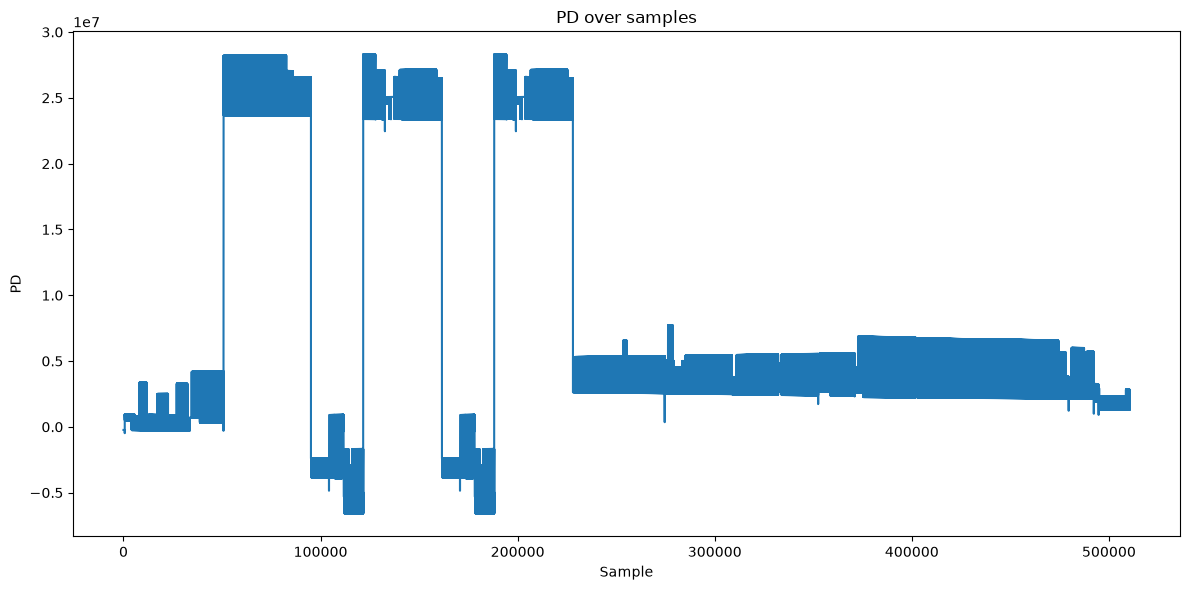

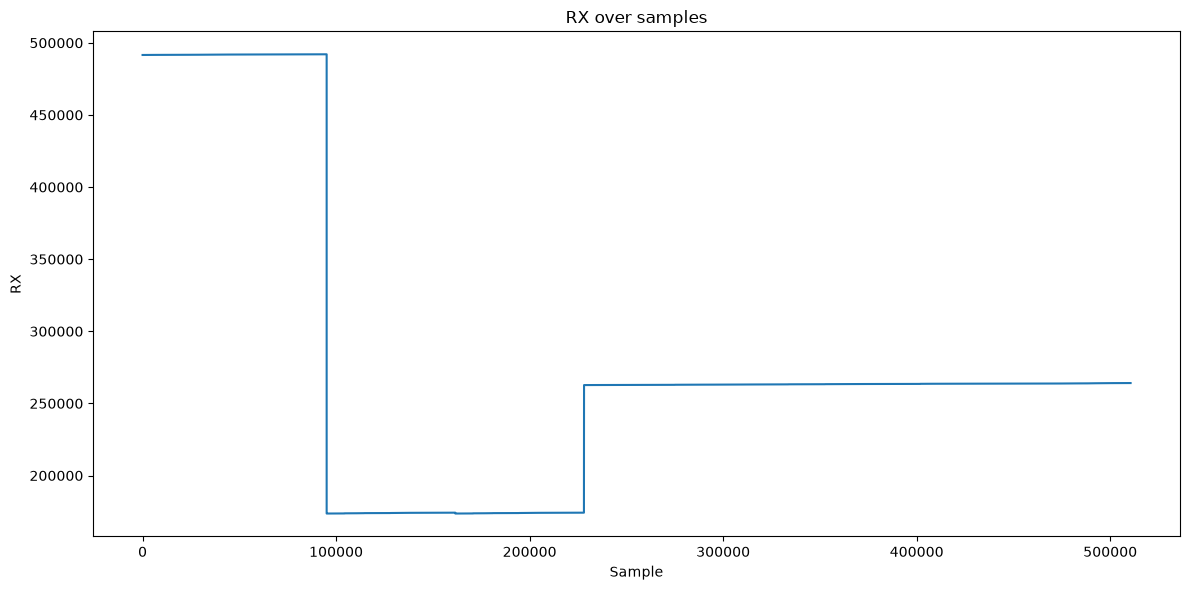

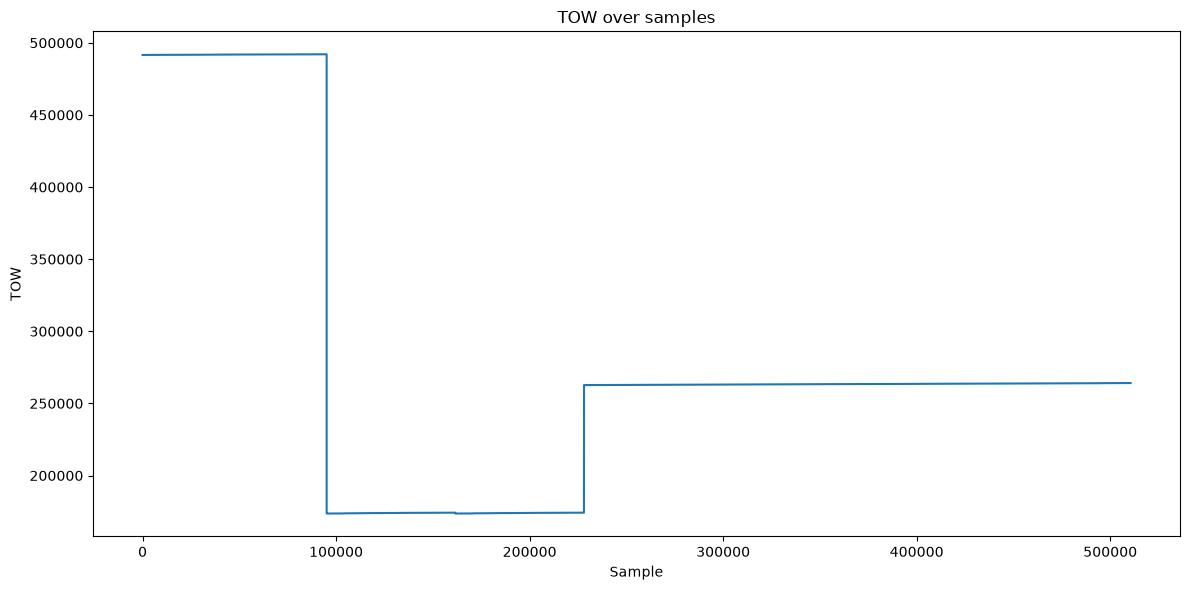

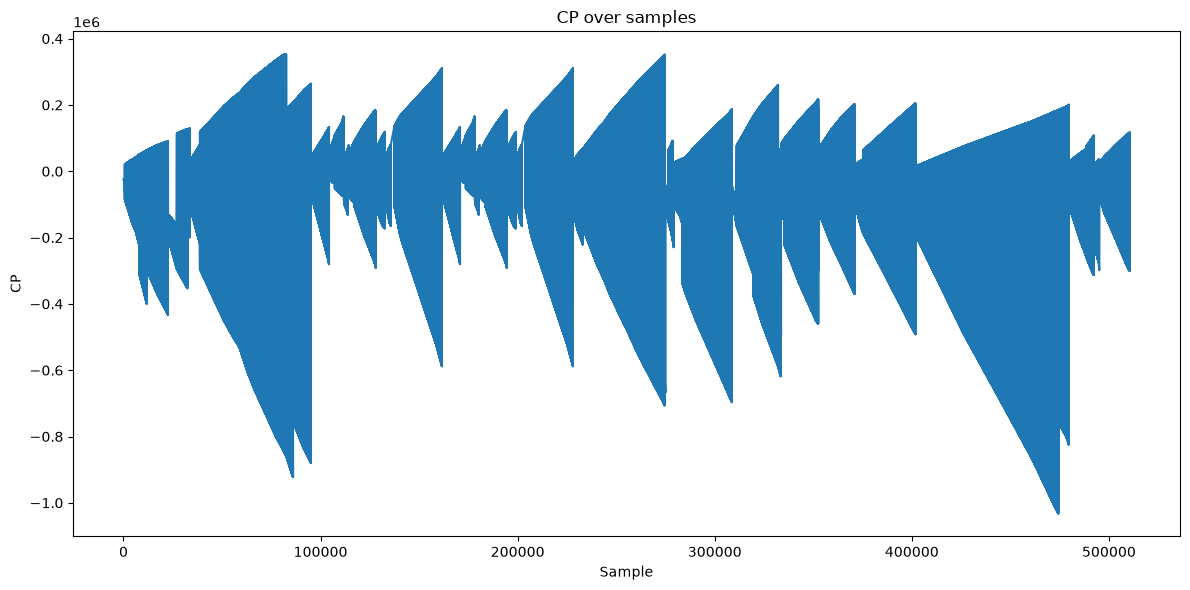

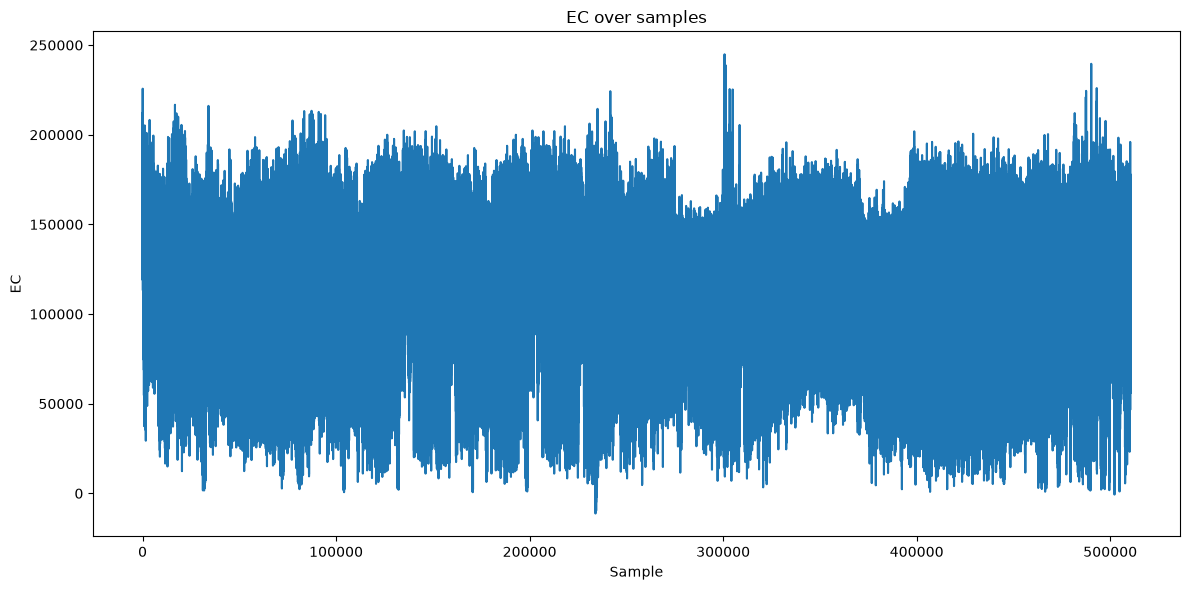

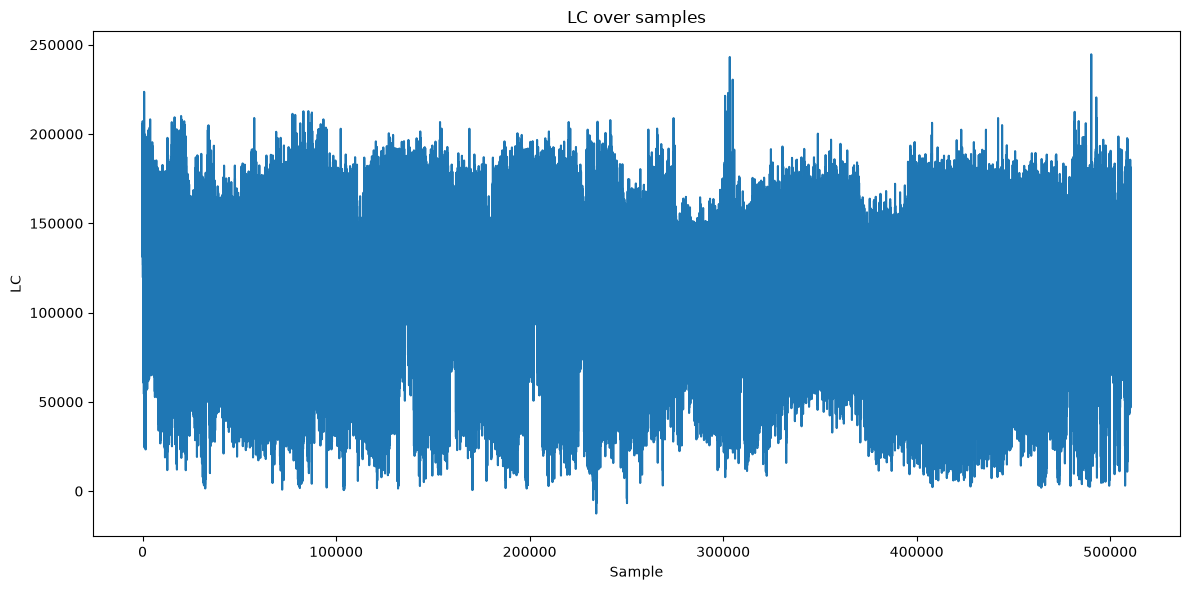

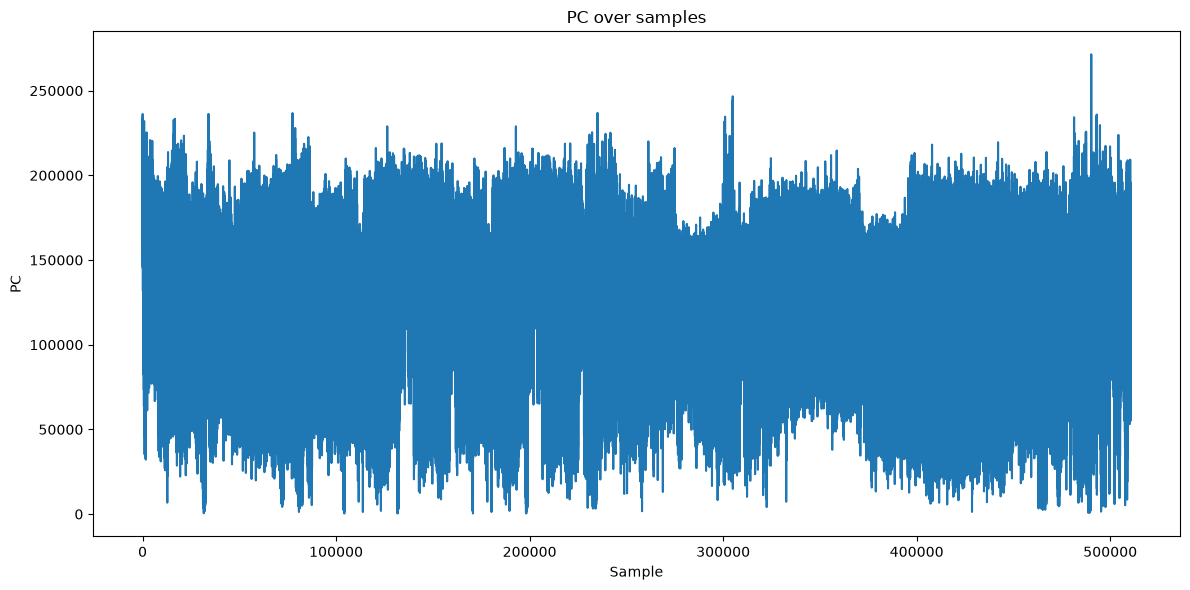

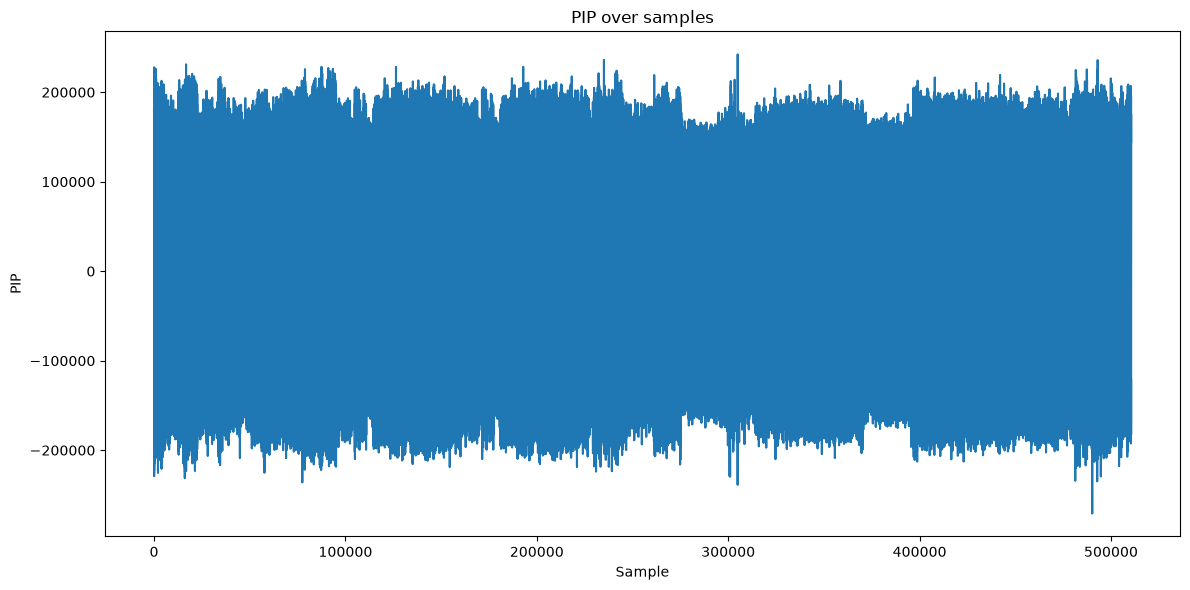

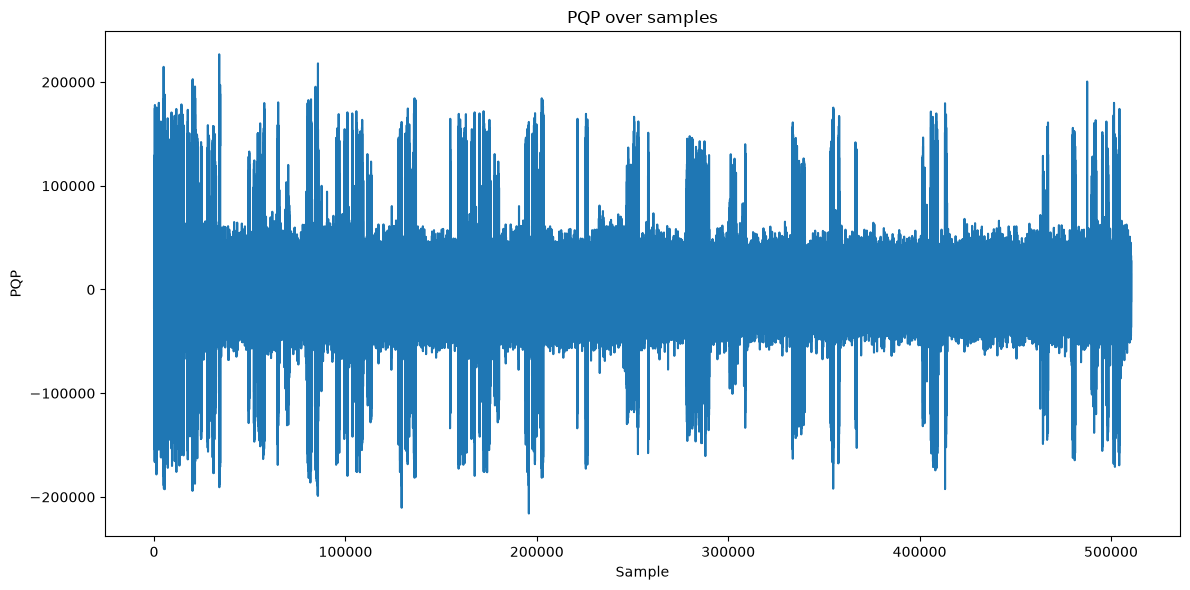

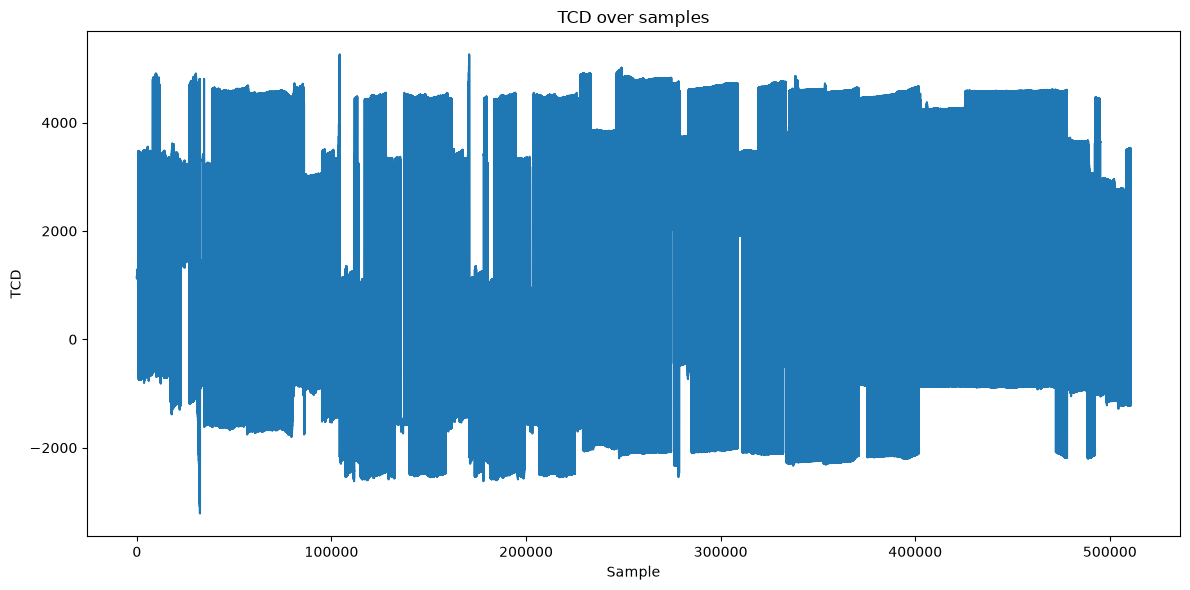

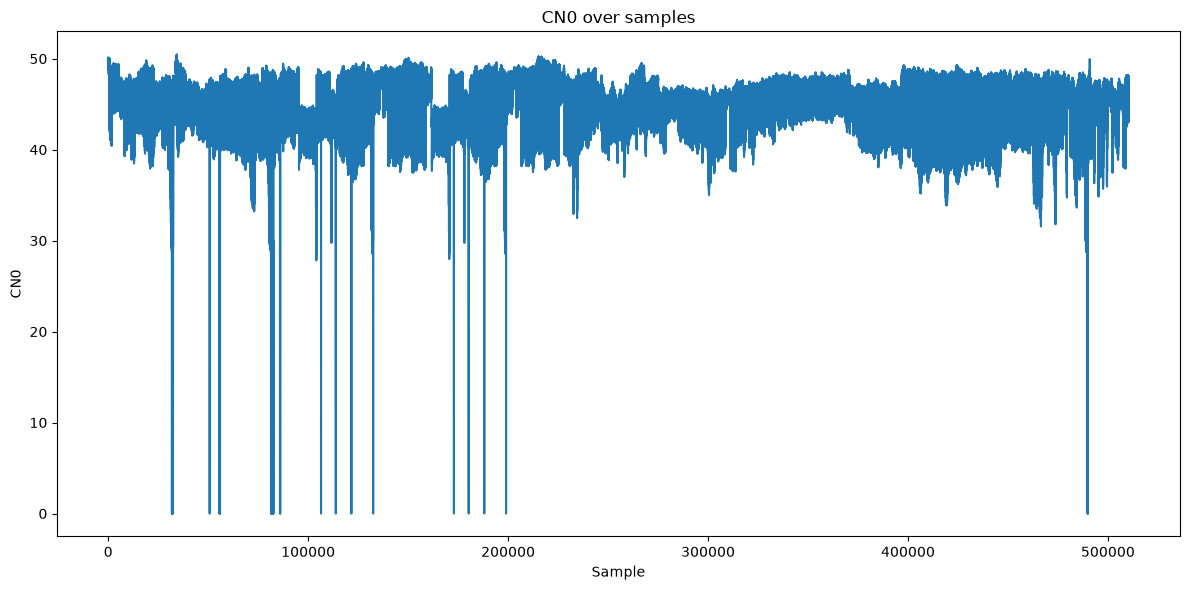

In [5]:
# line chart of features
for feature in features:
    if feature not in df.columns:
        continue  # Skip missing features

    series = df[feature]
    if pd.api.types.is_numeric_dtype(series):
        plt.figure(figsize=(12, 6))
        plt.plot(series)
        plt.xlabel("Sample")
        plt.ylabel(feature)
        plt.title(f"{feature} over samples")
        plt.tight_layout()
        plt.show()

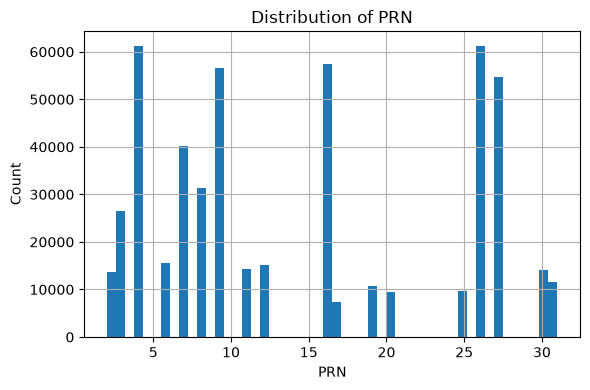

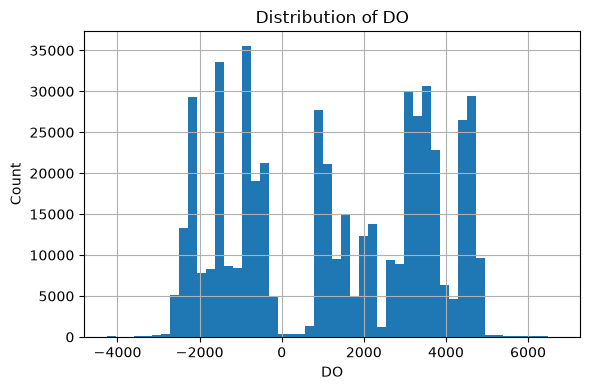

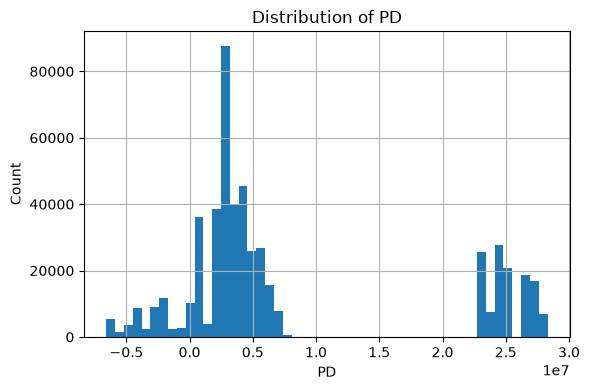

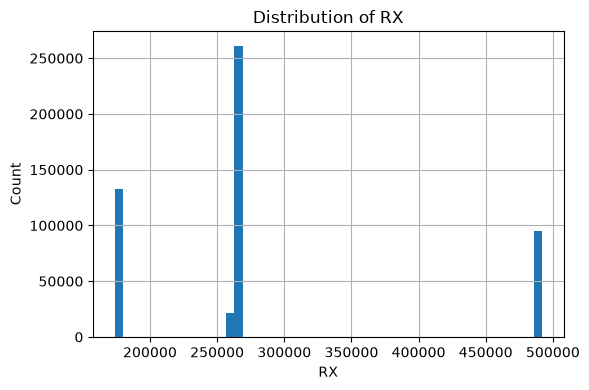

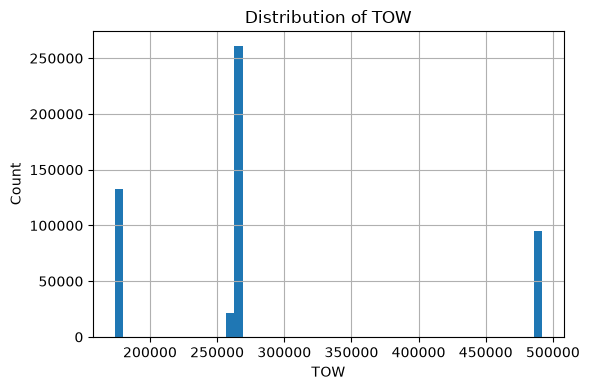

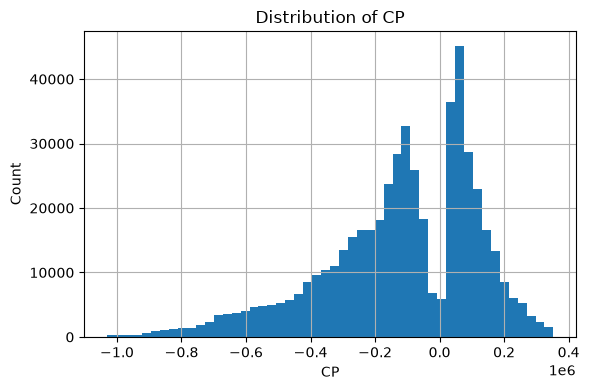

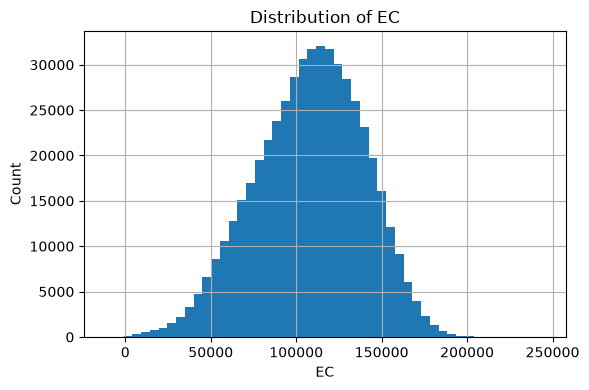

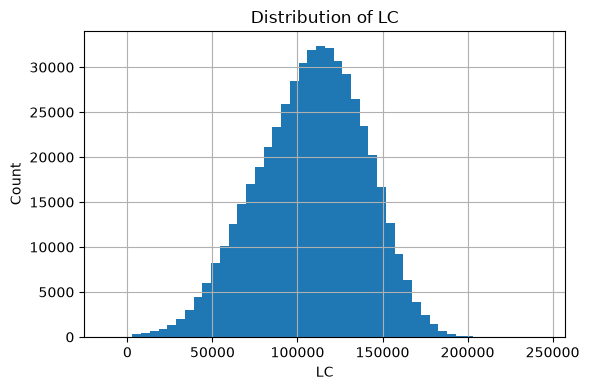

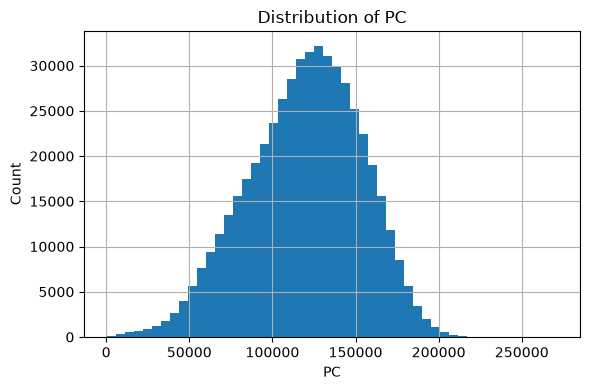

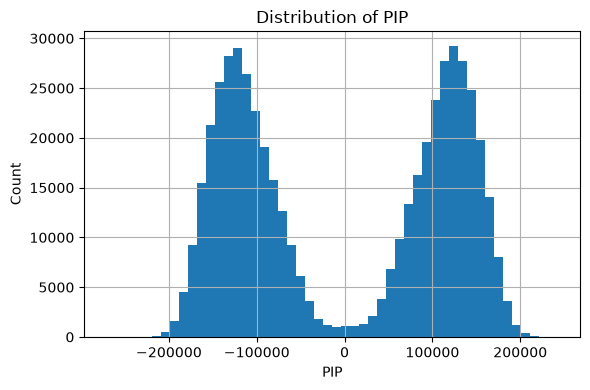

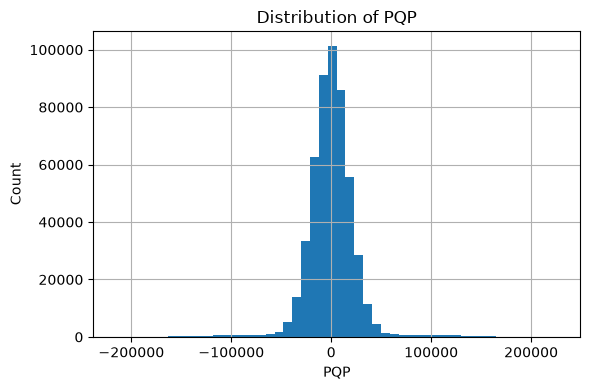

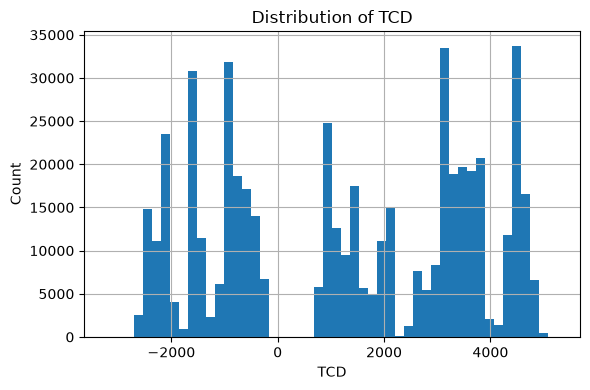

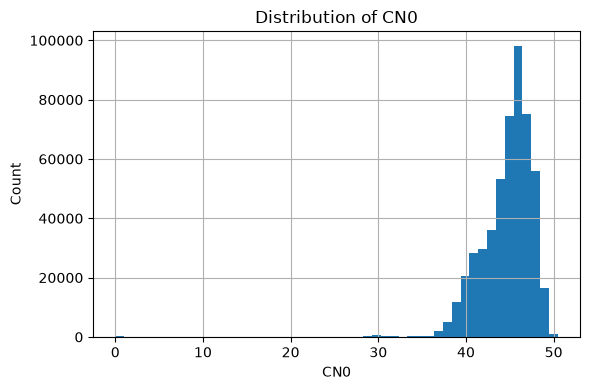

In [6]:
# Histogram of distribution of the features
for feature in features:
    plt.figure(figsize=(6, 4))
    df[feature].hist(bins=50)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

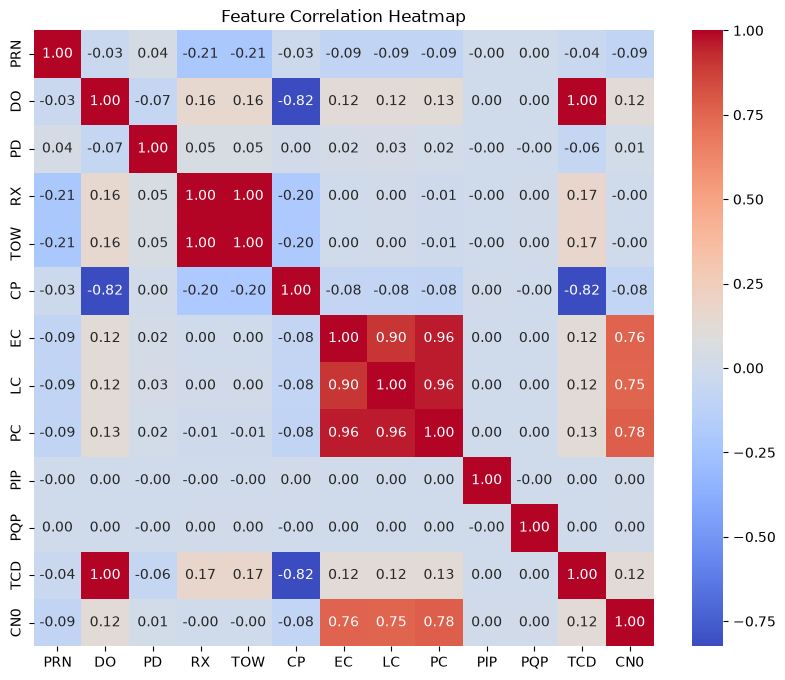

In [7]:
corr = df[features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

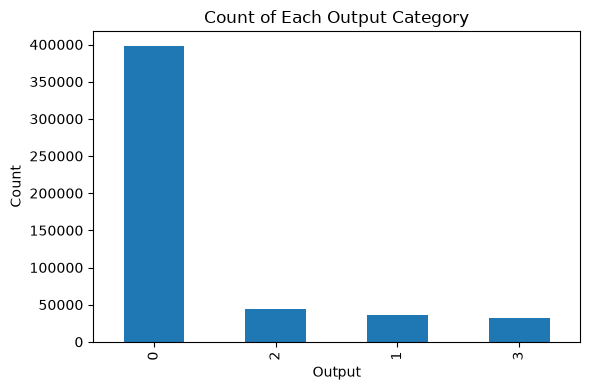

In [8]:
plt.figure(figsize=(6, 4))
df["Output"].value_counts().plot(kind='bar')
plt.title("Count of Each Output Category")
plt.xlabel("Output")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Class meanings:
# 0 = authentic GPS signal
# 1 = simple spoofing attack
# 2 = intermediate spoofing attack
# 3 = advanced spoofing attack

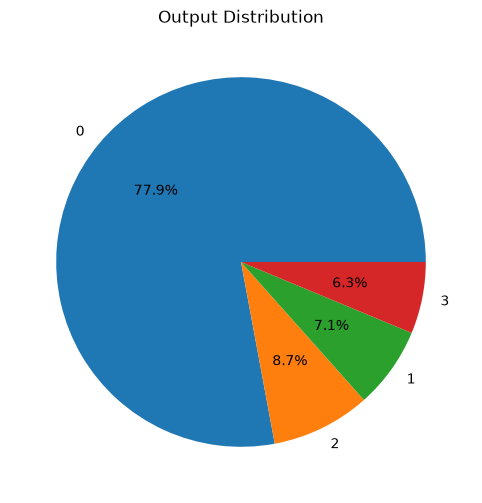

In [9]:
df["Output"].value_counts().plot.pie(autopct='%1.1f%%', figsize=(6, 6))
plt.title("Output Distribution")
plt.ylabel("")
plt.show()